📦 MNIST Veri Seti Nedir?
MNIST:

28x28 piksellik el yazısı rakam görüntüleri içerir (siyah-beyaz).

10 sınıf vardır: 0'dan 9'a kadar rakamlar.

Eğitim verisi: 60.000 örnek

Test verisi: 10.000 örnek

📌 Amaç: Görseli al, hangi rakam olduğunu tahmin et.

🧱 Model Mimarisi
Giriş Katmanı: 784 nöron (28×28 = 784 piksel)

Gizli Katman: 128 nöron (ReLU)

Çıkış Katmanı: 10 nöron (Softmax – çok sınıflı çıkış)

💡 Neden Softmax?
Çünkü çıkışta 10 sınıf var. Softmax, her sınıf için olasılık verir ve toplamı 1 olur.

# MNIST ile Görsel Tanıma – Keras Modeli
Bu Colab dosyasında, MNIST el yazısı rakam veri setiyle çalışan bir sinir ağı eğiteceğiz.
- Giriş: 28x28 = 784 piksel
- Çıkış: 10 sınıf (0-9 rakamları)
- Aktivasyonlar: ReLU ve Softmax

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical


## MNIST Verisini Yükleme ve Hazırlama

In [ ]:
# Veriyi yükle
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Yeniden şekillendir ve ölçeklendir
x_train = x_train.reshape(-1, 28*28) / 255.0
x_test = x_test.reshape(-1, 28*28) / 255.0

# Etiketleri one-hot encode yap
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print("Eğitim verisi şekli:", x_train.shape)
print("Test verisi şekli:", x_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Eğitim verisi şekli: (60000, 784)
Test verisi şekli: (10000, 784)


## Modelin Kurulması

In [ ]:
model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(784,)))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Modelin Eğitilmesi

In [ ]:
history = model.fit(x_train, y_train, epochs=10, validation_data=(x_test, y_test))
model.save('mnist_model.h5')

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9991 - loss: 0.0032 - val_accuracy: 0.9751 - val_loss: 0.1509
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9981 - loss: 0.0049 - val_accuracy: 0.9783 - val_loss: 0.1416
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9991 - loss: 0.0023 - val_accuracy: 0.9751 - val_loss: 0.1749
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9986 - loss: 0.0040 - val_accuracy: 0.9803 - val_loss: 0.1247
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9997 - loss: 0.0011 - val_accuracy: 0.9775 - val_loss: 0.1541
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9985 - loss: 0.0051 - val_accuracy: 0.9800 - val_loss: 0.1456
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9999 - loss: 5.4628e-04 - val_accuracy: 0.9790 - val_loss: 0.1412
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9982 - loss: 0.005

## Eğitim ve Doğrulama Grafikleri

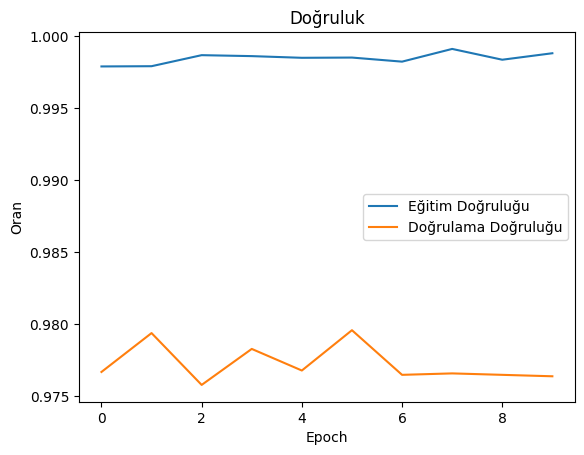

In [ ]:
plt.plot(history.history['accuracy'], label='Eğitim Doğruluğu')
plt.plot(history.history['val_accuracy'], label='Doğrulama Doğruluğu')
plt.title("Doğruluk")
plt.xlabel("Epoch")
plt.ylabel("Oran")
plt.legend()
plt.show()


## Test Verisinden Örnek ve Tahmin

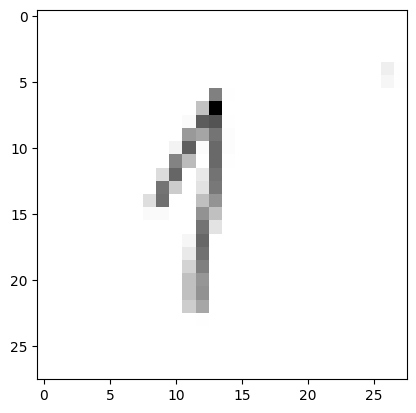

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
Tahmin edilen rakam: 3
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


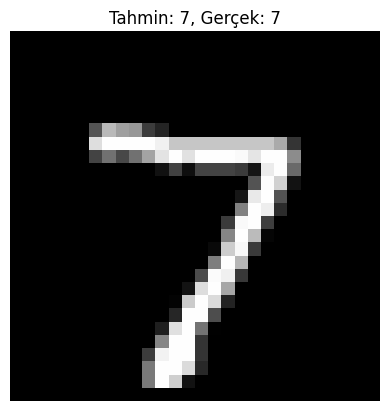

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/mnist_model.h5")

from PIL import Image
import numpy as np

# Görseli yükle
img = Image.open("/content/Ekran görüntüsü 2025-07-07 112630.png").convert('L')   # Gri tonlama
img = img.resize((28, 28))                   # 28x28 boyutlandır

# Görseli görselleştir
import matplotlib.pyplot as plt
plt.imshow(img, cmap='gray')
plt.show()

# Görseli normalize ve modele uygun şekle getir
# CNN gibi kanal eklemeye gerek yok
img_array = np.array(img) / 255.0            # normalize
img_array = img_array.reshape(1, 28*28)      # (1, 784) şekline getir



prediction = model.predict(img_array)
predicted_class = np.argmax(prediction)

print("Tahmin edilen rakam:", predicted_class)

index = 0  # ilk örnek

sample = x_test[index].reshape(1, -1)
tahmin = model.predict(sample)

plt.imshow(x_test[index].reshape(28, 28), cmap='gray')
plt.title(f"Tahmin: {np.argmax(tahmin)}, Gerçek: {np.argmax(y_test[index])}")
plt.axis('off')
plt.show()
